# Extremum graphs of real volumes (Open SciVis Datasets)

`extremum_graph_demo.ipynb` tested the pipeline on synthetic point clouds with
known answers. This notebook runs the same code on six small 3D volumes from
Pavol Klacansky's [Open SciVis Datasets](http://klacansky.com/open-scivis-datasets/)
collection and shows what their extremum graphs look like.

| dataset | grid | what it is |
|---|---|---|
| `nucleon` | 41³ | two-body probability of a nucleon in an ¹⁶O nucleus |
| `hydrogen_atom` | 128³ | electron probability of a hydrogen atom in a strong magnetic field |
| `fuel` | 64³ | fuel injection into a combustion chamber |
| `neghip` | 64³ | electron probability in a protein molecule |
| `silicium` | 98×34×34 | silicon crystal lattice |
| `marschner_lobb` | 41³ | Marschner–Lobb test signal (high-frequency rings) |

The order goes from simple to complex graphs.

**How the graph is computed.** A volume is a regular grid, so the neighbour
graph is the grid itself (`grid_graph`, 6 neighbours per voxel); no kNN is
needed. Values are scaled to [0, 1]. Then `extremum_graph` and `simplify`
run exactly as on the point clouds.

**Reading the pictures.** Orange triangles are maxima (peaks), blue squares
are saddles. A solid line joins a saddle to the two peaks it *merges*; a
dashed line belongs to a saddle that *closes a loop* (the two peaks were
already connected through higher saddles). The grey background is a maximum
intensity projection (MIP) of the volume, darker means higher.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import networkx as nx

from pipeline.volume_loader import SMALL_DATASETS, download, load_volume
from pipeline.neighbor_graph import grid_graph
from pipeline.extremum_graph import extremum_graph

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#888888", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555", "text.color": "#222222",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
PEAK, SADDLE, LINK = "#D55E00", "#0072B2", "#333333"
REGION = ["#D55E00", "#0072B2", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]  # fixed order, as in the demo notebook

# Downloads only what is missing (about 2.9 MB in total) into data/klacansky/.
for name in SMALL_DATASETS:
    download(name)

## Helpers

`compute` builds the grid graph and the raw extremum graph. `show` draws one
dataset in four panels:

1. **MIP + graph**: the volume projected along z, with the simplified graph
   projected the same way.
2. **Persistence**: every peak's persistence, sorted. The threshold (dashed)
   decides which peaks survive `simplify`. The y axis is logarithmic because
   the noise peaks sit orders of magnitude below the real ones.
3. **3D view**: the brightest voxels (grey) with the graph in 3D. When there
   are at most six peaks the voxels are coloured by the region they climb to.
4. **Abstract graph**: the same graph with a force-directed layout, no spatial
   information. Peak size follows the number of voxels in its region. This
   is the raw material the topological spine will lay out.

In [2]:
def compute(name):
    vol = load_volume(name)
    t = time.time()
    eg = extremum_graph(vol.values.reshape(-1), grid_graph(vol.shape))
    print(f"{vol}\n  raw:  {eg}   ({time.time() - t:.1f} s)")
    return vol, eg


def _links(eg, P, draw, merge_kw, loop_kw):
    """Call draw(a, b, **kw) for every peak-saddle link, solid for merge saddles, dashed for loops."""
    for p, s in eg.edges:
        kw = merge_kw if eg.saddle_is_merge[s] else loop_kw
        draw(P[eg.peaks[p]], P[eg.saddles[s]], **kw)


def _marker_sizes(eg):
    many = eg.num_peaks > 30
    return (40, 28) if many else (110, 70)


def draw_mip(ax, vol, eg):
    mip = vol.values.max(axis=0)                     # project along z -> (y, x)
    ax.imshow(mip, cmap="Greys", origin="lower", vmin=0, vmax=1.15, interpolation="nearest")
    Pp, Ps = vol.coords(eg.peaks)[:, :2], vol.coords(eg.saddles)[:, :2]
    P = {**{("p", i): Pp[i] for i in range(eg.num_peaks)}, **{("s", j): Ps[j] for j in range(eg.num_saddles)}}
    stroke = [pe.Stroke(linewidth=3.2, foreground="white"), pe.Normal()]
    for p, s in eg.edges:
        a, b = P[("p", p)], P[("s", s)]
        if eg.saddle_is_merge[s]:
            ax.plot([a[0], b[0]], [a[1], b[1]], color=LINK, lw=1.3, zorder=2, path_effects=stroke)
        else:
            ax.plot([a[0], b[0]], [a[1], b[1]], color=LINK, lw=0.9, ls=(0, (3, 2)), alpha=0.7, zorder=2)
    sp, ss = _marker_sizes(eg)
    ax.scatter(*Ps.T, marker="s", s=ss, c=SADDLE, edgecolors="white", linewidths=1.0, zorder=3)
    ax.scatter(*Pp.T, marker="^", s=sp, c=PEAK, edgecolors="white", linewidths=1.0, zorder=4)
    ax.set_xlabel("x (voxels)"); ax.set_ylabel("y (voxels)")
    ax.set_title(f"MIP along z: {eg.num_peaks} peaks, {eg.num_saddles} saddles")


def draw_persistence(ax, eg_raw, threshold):
    pers = np.sort(eg_raw.peak_persistence[np.isfinite(eg_raw.peak_persistence)])[::-1]
    pers = np.maximum(pers, 1e-4)                    # zero-persistence plateau peaks, shown at the floor
    keep = pers >= threshold
    x = np.arange(1, len(pers) + 1)
    ax.scatter(x[~keep], pers[~keep], s=14, c="#9a9a9a", linewidths=0, label=f"removed ({(~keep).sum():,})")
    ax.scatter(x[keep], pers[keep], s=30, c=PEAK, edgecolors="white", linewidths=0.8, zorder=3,
               label=f"kept ({keep.sum():,} + global max)")
    ax.axhline(threshold, color=LINK, lw=1.0, ls="--")
    ax.text(len(pers), threshold * 1.15, f"threshold {threshold}", ha="right", va="bottom", fontsize=8)
    ax.set_yscale("log"); ax.set_ylim(8e-5, 1.5)
    ax.set_xscale("log" if len(pers) > 200 else "linear")
    ax.set_xlabel("peak, sorted by persistence"); ax.set_ylabel("persistence (log)")
    ax.set_title(f"Persistence of the {eg_raw.num_peaks:,} raw peaks")
    ax.legend(loc="lower left", fontsize=8, frameon=True, framealpha=0.9)


def draw_3d(ax, vol, eg, iso=None, max_pts=7000, seed=0):
    v = vol.values.reshape(-1)
    if iso is None:                                  # brightest voxels: top 8 % of the non-background
        iso = np.quantile(v[v > v.min()], 0.92)
    idx = np.flatnonzero(v >= iso)
    idx = np.random.default_rng(seed).choice(idx, min(max_pts, len(idx)), replace=False)
    P = vol.coords(idx)
    if eg.num_peaks <= len(REGION):
        colors = np.array(REGION)[eg.region[idx]]
        ax.scatter(*P.T, c=colors, s=2, alpha=0.25, linewidths=0, depthshade=False)
    else:
        ax.scatter(*P.T, c=v[idx], cmap="Greys", vmin=0, vmax=1.3, s=2, alpha=0.35, linewidths=0, depthshade=False)
    Pp, Ps = vol.coords(eg.peaks), vol.coords(eg.saddles)
    for p, s in eg.edges:
        a, b = Pp[p], Ps[s]
        if eg.saddle_is_merge[s]:
            ax.plot(*zip(a, b), color=LINK, lw=1.4)
        else:
            ax.plot(*zip(a, b), color=LINK, lw=0.8, ls=(0, (3, 2)), alpha=0.6)
    sp, ss = _marker_sizes(eg)
    if eg.num_peaks > 30:
        sp, ss = 25, 6
    ax.scatter(*Ps.T, marker="s", s=ss, c=SADDLE, edgecolors="white", linewidths=0.5 if ss < 10 else 1.0, depthshade=False)
    ax.scatter(*Pp.T, marker="^", s=sp, c=PEAK, edgecolors="white", linewidths=1.0, depthshade=False)
    nz, ny, nx_ = vol.shape
    ax.set_box_aspect((nx_, ny, nz))
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.tick_params(labelsize=7)
    what = "coloured by region" if eg.num_peaks <= len(REGION) else "grey by value"
    ax.set_title(f"3D: voxels with value ≥ {iso:.2f}, {what}")


def draw_abstract(ax, eg, seed=3):
    G = nx.Graph()
    G.add_nodes_from(("p", i) for i in range(eg.num_peaks))
    G.add_nodes_from(("s", j) for j in range(eg.num_saddles))
    for p, s in eg.edges:
        G.add_edge(("p", int(p)), ("s", int(s)), merge=bool(eg.saddle_is_merge[s]))
    pos = nx.spring_layout(G, seed=seed, iterations=300)
    merge = [e for e in G.edges if G.edges[e]["merge"]]
    loop = [e for e in G.edges if not G.edges[e]["merge"]]
    many = eg.num_peaks > 30
    nx.draw_networkx_edges(G, pos, edgelist=loop, ax=ax, edge_color=LINK, width=0.7, style=(0, (3, 2)), alpha=0.6)
    nx.draw_networkx_edges(G, pos, edgelist=merge, ax=ax, edge_color=LINK, width=1.0 if many else 1.6)
    nx.draw_networkx_nodes(G, pos, nodelist=[("s", j) for j in range(eg.num_saddles)], node_shape="s",
                           node_size=18 if many else 90, node_color=SADDLE, edgecolors="white",
                           linewidths=0.8 if many else 1.4, ax=ax)
    size = eg.region_size / eg.region_size.max()
    nx.draw_networkx_nodes(G, pos, nodelist=[("p", i) for i in range(eg.num_peaks)], node_shape="^",
                           node_size=(30 + 250 * size) if many else (200 + 1200 * size),
                           node_color=PEAK, edgecolors="white", linewidths=0.8 if many else 1.4, ax=ax)
    if eg.num_peaks <= 12:
        nx.draw_networkx_labels(G, pos, labels={("p", i): str(i) for i in range(eg.num_peaks)},
                                font_size=8, font_color="white", font_weight="bold", ax=ax)
    ax.set_axis_off(); ax.margins(0.08)
    ax.set_title("Abstract graph (force-directed), peak size = region size")


def show(vol, eg_raw, threshold, iso=None):
    eg = eg_raw.simplify(threshold)
    n_loop = int((~eg.saddle_is_merge).sum())
    print(f"  simplified at {threshold}: {eg}")
    fig = plt.figure(figsize=(14, 10.5))
    nz, ny, nx_ = vol.shape
    if nx_ > 2 * ny:                                 # wide volume: give the MIP two thirds of the top row
        gs = fig.add_gridspec(2, 3, height_ratios=(0.8, 1.2))
        slots = (gs[0, :2], gs[0, 2], gs[1, 0], gs[1, 1:])
    else:
        gs = fig.add_gridspec(2, 2)
        slots = (gs[0, 0], gs[0, 1], gs[1, 0], gs[1, 1])
    draw_mip(fig.add_subplot(slots[0]), vol, eg)
    draw_persistence(fig.add_subplot(slots[1]), eg_raw, threshold)
    draw_3d(fig.add_subplot(slots[2], projection="3d"), vol, eg, iso=iso)
    draw_abstract(fig.add_subplot(slots[3]), eg)
    legend = [Line2D([], [], marker="^", ls="", color=PEAK, ms=9, mec="white", label="maximum (peak)"),
              Line2D([], [], marker="s", ls="", color=SADDLE, ms=7, mec="white", label="saddle"),
              Line2D([], [], color=LINK, lw=1.5, label="link of a merge saddle"),
              Line2D([], [], color=LINK, lw=1.0, ls=(0, (3, 2)), label=f"link of a loop saddle ({n_loop})")]
    fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False, fontsize=9)
    fig.suptitle(f"{vol.name}: extremum graph after simplify({threshold})", x=0.01, ha="left",
                 fontsize=13, fontweight="bold")
    plt.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.show()
    return eg


def peak_table(vol, eg, limit=12):
    print("peak  position (x, y, z)   value  persistence  voxels in region")
    for i in range(min(eg.num_peaks, limit)):
        pers = "inf (global)" if np.isinf(eg.peak_persistence[i]) else f"{eg.peak_persistence[i]:.3f}"
        x, y, z = vol.coords(eg.peaks[i]).astype(int)
        print(f"{i:4d}  ({x:3d}, {y:3d}, {z:3d})      {eg.peak_values[i]:.3f}  {pers:>12}  {eg.region_size[i]:>10,}")
    if eg.num_peaks > limit:
        print(f"  ... {eg.num_peaks - limit} more")

RESULTS = {}

## 1. `nucleon`

A probability density with a few large lobes. The field is 8-bit, so
neighbouring voxels often have exactly the same value. Ties are broken by
voxel index, which makes every flat patch a "peak" of persistence 0. Those
show up at the floor of the persistence plot and are removed by any
threshold above 0.

Volume('nucleon', 41x41x41 uint8, raw range 0..249)
  raw:  ExtremumGraph(301 peaks, 760 saddles (460 close a loop), N=68921)   (0.2 s)
  simplified at 0.005: ExtremumGraph(6 peaks, 9 saddles (4 close a loop), N=68921)


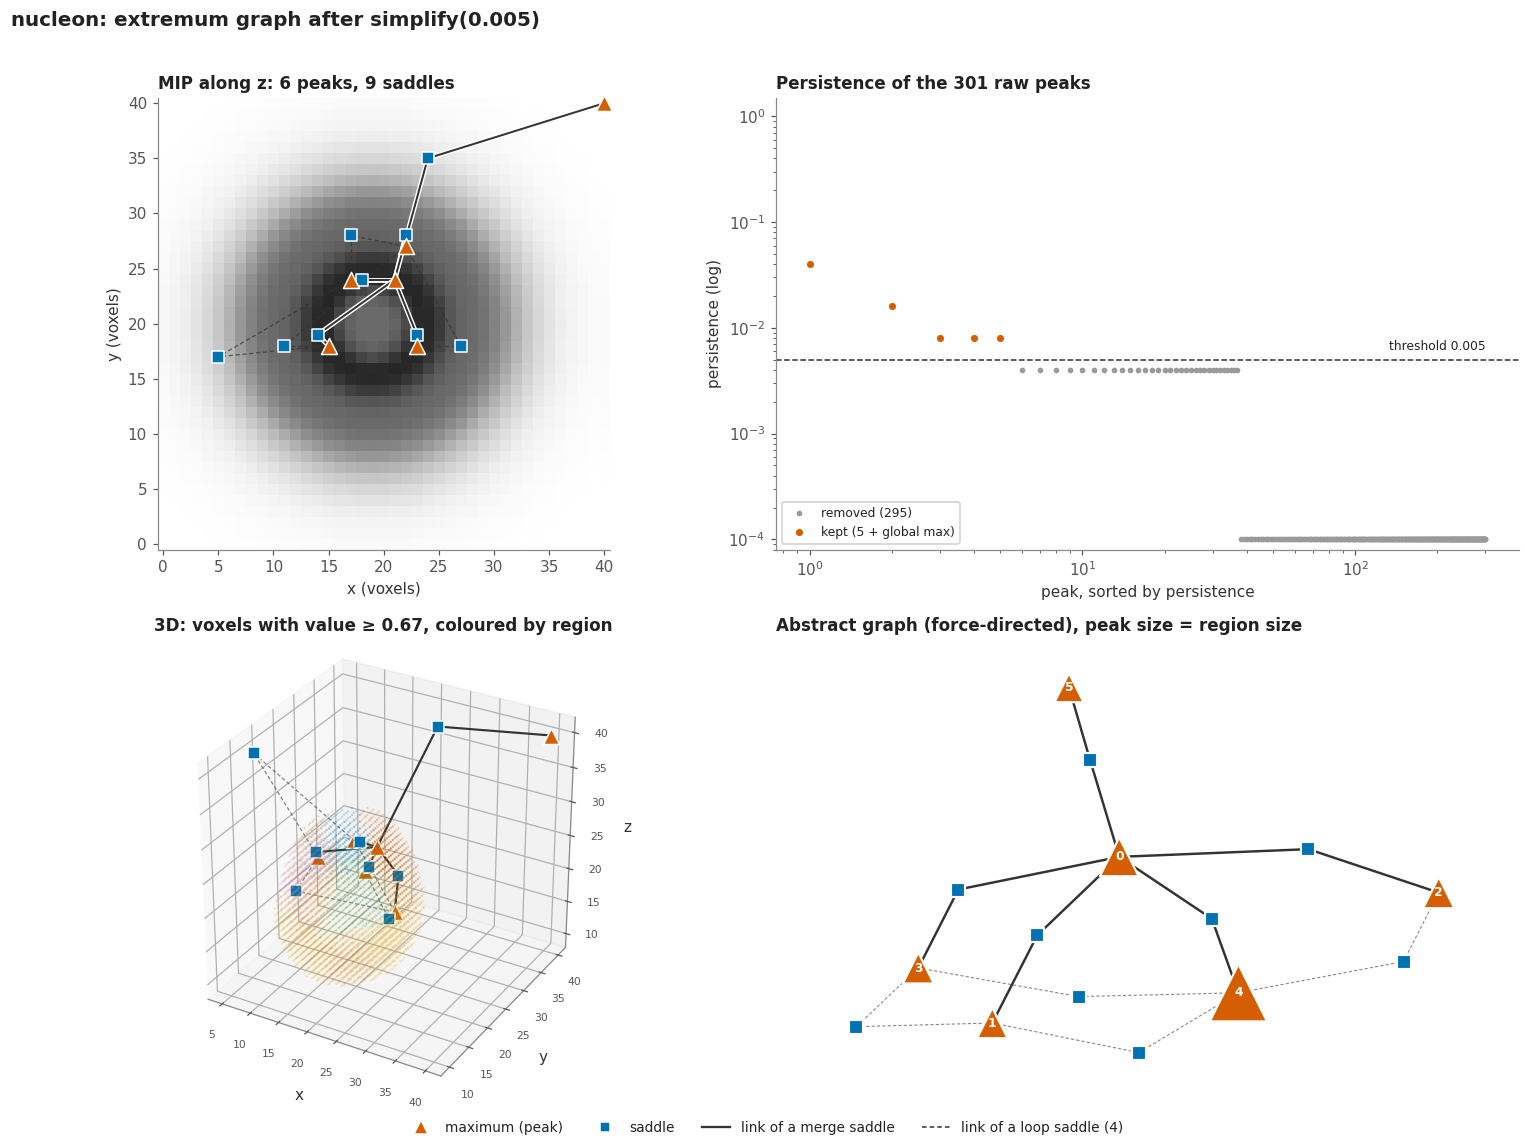

peak  position (x, y, z)   value  persistence  voxels in region
   0  ( 21,  24,  27)      1.000  inf (global)      12,613
   1  ( 17,  24,  27)      1.000         0.008       5,551
   2  ( 23,  18,  27)      1.000         0.008       6,126
   3  ( 15,  18,  27)      1.000         0.008       5,943
   4  ( 22,  27,  16)      0.775         0.016      34,192
   5  ( 40,  40,  40)      0.040         0.040       4,496


In [3]:
vol, eg_raw = compute("nucleon")
eg = show(vol, eg_raw, threshold=0.005)
peak_table(vol, eg)
RESULTS["nucleon"] = (vol, eg_raw, eg, 0.005)

**What it looks like.** Four lobes around the centre (peaks 0 to 3), each
with the top value 1.0, and a weaker lobe below them (peak 4). The four top
lobes are separated by very shallow dips: their persistence is 0.008, two
8-bit steps (one step is 1/249 = 0.004). All the removed peaks have
persistence 0.004 or 0, so they are single-step quantisation noise and the
threshold 0.005 sits between noise and signal.

Peak 5 is not part of the nucleon. It is a single voxel of value 10 in the
corner (40, 40, 40), the last voxel of the file, surrounded by zeros. The
zero background is one big plateau, and since ties are broken by index, the
plateau climbs to its highest-index voxel, which is that corner. The same
corner voxel appears in `hydrogen_atom`.

## 2. `hydrogen_atom`

2 million voxels, still about six seconds. The raw graph has thousands of
peaks, nearly all of persistence 0 (flat 8-bit plateaus in the empty
space).

Volume('hydrogen_atom', 128x128x128 uint8, raw range 0..250)
  raw:  ExtremumGraph(6184 peaks, 24951 saddles (18768 close a loop), N=2097152)   (6.6 s)
  simplified at 0.02: ExtremumGraph(5 peaks, 4 saddles (0 close a loop), N=2097152)


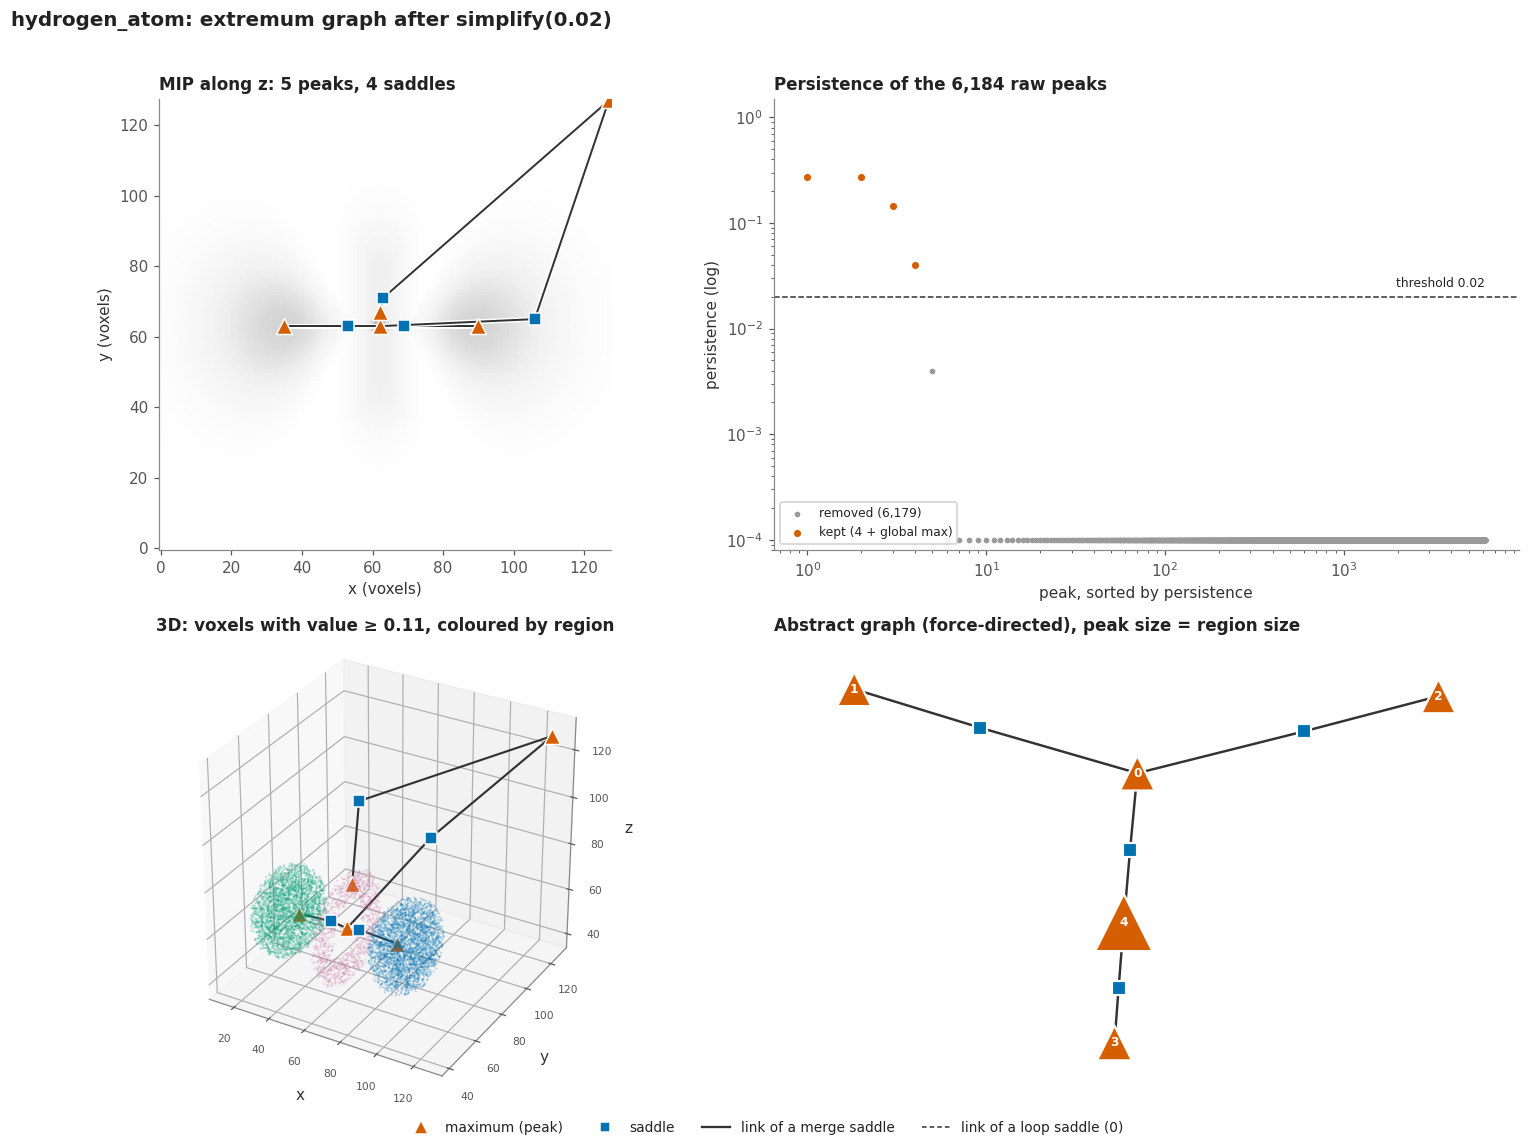

peak  position (x, y, z)   value  persistence  voxels in region
   0  ( 62,  63,  63)      1.000  inf (global)     272,119
   1  ( 90,  63,  63)      0.320         0.272     252,614
   2  ( 35,  63,  63)      0.320         0.272     258,822
   3  ( 62,  67,  80)      0.144         0.144     275,211
   4  (127, 127, 127)      0.040         0.040   1,038,386


In [4]:
vol, eg_raw = compute("hydrogen_atom")
eg = show(vol, eg_raw, threshold=0.02)
peak_table(vol, eg)
RESULTS["hydrogen_atom"] = (vol, eg_raw, eg, 0.02)

**What it looks like.** A clean tree with no loops: the central lobe (peak
0, the global maximum) joined to two equal side lobes (1 and 2), plus a
weaker lobe above them (3). The persistence plot has a gap of nearly two
orders of magnitude, so any threshold between about 0.005 and 0.04 gives
the same result.

Peak 4 is the same artefact as in `nucleon`: one voxel of value 10 at the
last corner (127, 127, 127). Its "region" is the zero background, half the
volume, and it hangs off the tree through saddles of value 0. Peak 3 is
linked only through it, because the lobe of peak 3 is separated from the
others by voxels of value 0. A front end should drop such zero-valued
saddles (or treat the zero plateau as "no data").

## 3. `fuel`

95 % of the voxels are 0 (no fuel). The jet is a single elongated structure
with several local density maxima along it.

Volume('fuel', 64x64x64 uint8, raw range 0..255)
  raw:  ExtremumGraph(88 peaks, 332 saddles (245 close a loop), N=262144)   (0.7 s)
  simplified at 0.1: ExtremumGraph(6 peaks, 6 saddles (1 close a loop), N=262144)


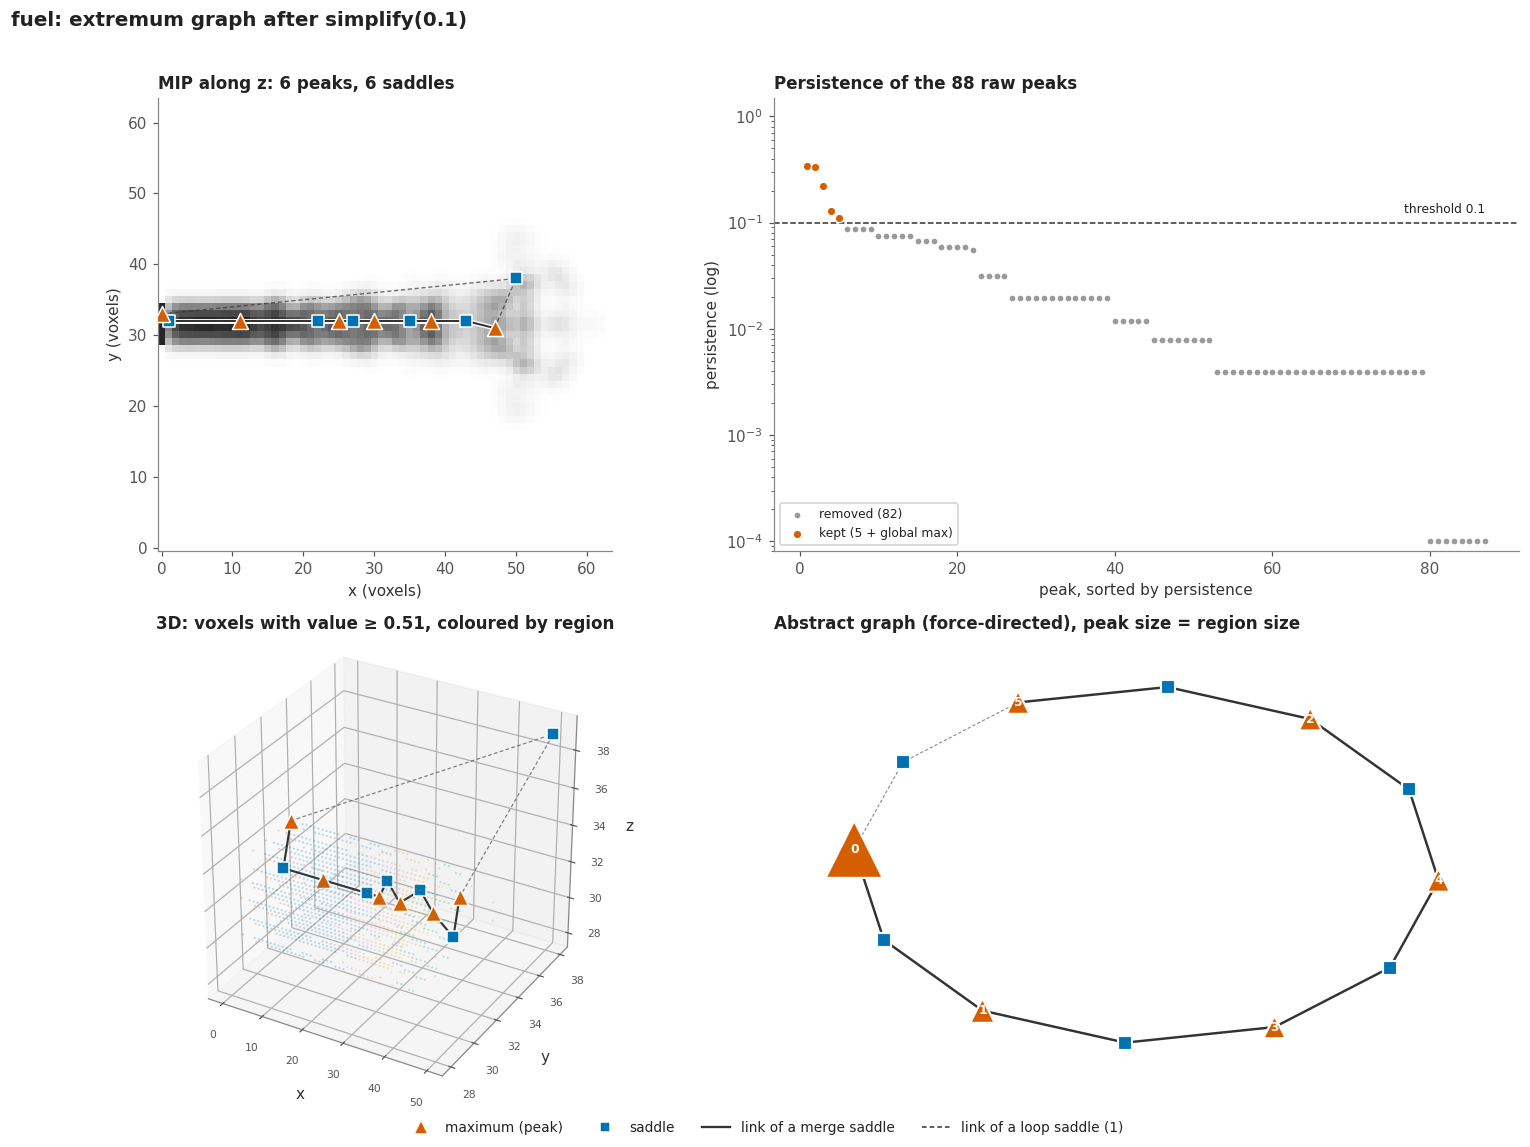

peak  position (x, y, z)   value  persistence  voxels in region
   0  (  0,  33,  34)      1.000  inf (global)     234,080
   1  ( 11,  32,  32)      1.000         0.341      11,000
   2  ( 38,  32,  32)      0.855         0.333       4,837
   3  ( 25,  32,  32)      0.824         0.129       2,726
   4  ( 30,  32,  32)      0.800         0.110       5,040
   5  ( 47,  31,  34)      0.541         0.220       4,461


In [5]:
vol, eg_raw = compute("fuel")
eg = show(vol, eg_raw, threshold=0.1)
peak_table(vol, eg)
RESULTS["fuel"] = (vol, eg_raw, eg, 0.1)

**What it looks like.** Persistence falls off gradually, with no single gap,
so the threshold is a judgement call. At 0.1 six peaks remain: the global
maximum at the nozzle (x = 0), whose region covers almost all of the empty
space, and five local maxima further along the jet axis (y ≈ 32, z ≈ 32).
One saddle closes a loop.

## 4. `neghip`

An electron density around a protein: several separate blobs of high
density.

Volume('neghip', 64x64x64 uint8, raw range 0..255)
  raw:  ExtremumGraph(900 peaks, 2627 saddles (1728 close a loop), N=262144)   (0.7 s)
  simplified at 0.2: ExtremumGraph(22 peaks, 28 saddles (7 close a loop), N=262144)


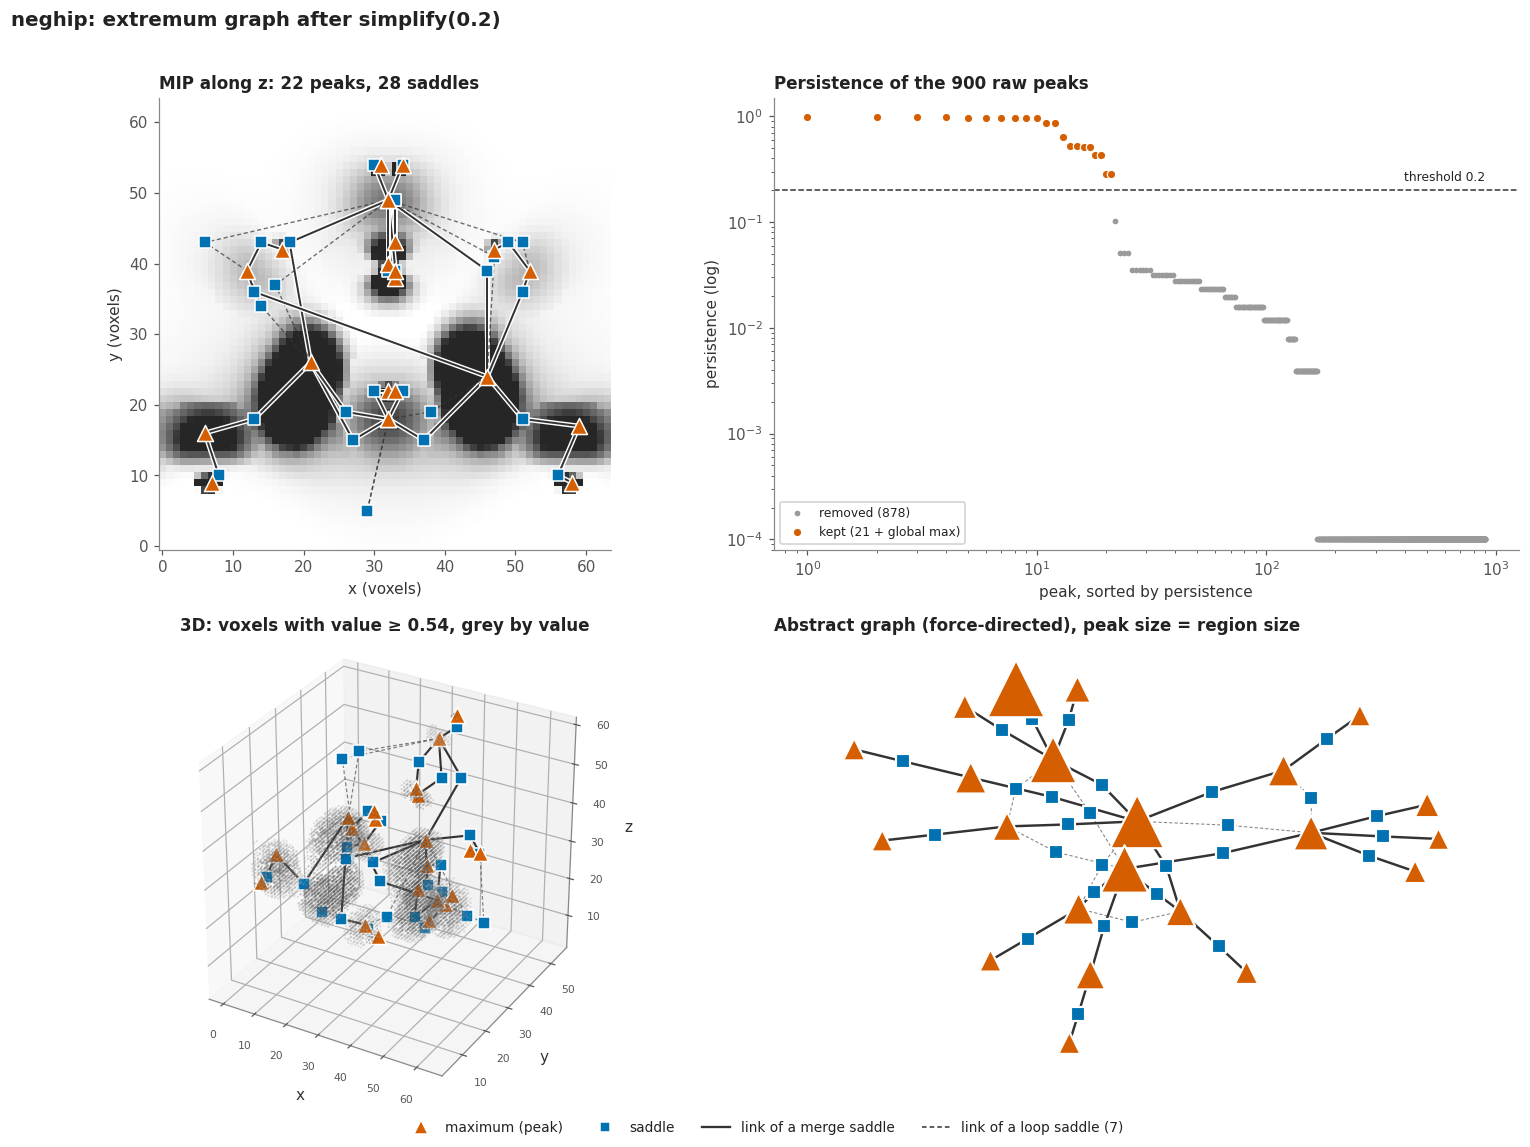

peak  position (x, y, z)   value  persistence  voxels in region
   0  ( 34,  54,  57)      1.000  inf (global)      55,454
   1  ( 32,  22,  48)      1.000         0.980       1,549
   2  ( 33,  38,  46)      1.000         0.961       5,028
   3  ( 32,  40,  43)      1.000         0.859       2,952
   4  ( 46,  24,  43)      1.000         0.957      47,919
   5  ( 21,  26,  42)      1.000         0.643      35,328
   6  ( 59,  17,  36)      1.000         0.427      11,021
   7  (  6,  16,  34)      1.000         0.427       8,571
   8  ( 58,   9,  34)      1.000         0.965         397
   9  ( 17,  42,  32)      1.000         0.980         112
  10  ( 47,  42,  31)      1.000         0.980         344
  11  (  7,   9,  31)      1.000         0.965         429
  ... 10 more


In [6]:
vol, eg_raw = compute("neghip")
eg = show(vol, eg_raw, threshold=0.2)
peak_table(vol, eg)
RESULTS["neghip"] = (vol, eg_raw, eg, 0.2)

**What it looks like.** Many peaks reach the top value 1.0 (the field is
clipped at 255), and most persistence values come in equal pairs, which
matches the mirror symmetry visible in the MIP. The persistence plot has a
gap between 0.29 and 0.10; the threshold 0.2 sits in it. (At 0.1 one more
peak, of persistence 0.102, would survive.) The graph is mostly a tree
around the two big blobs (peaks 4 and 5 in the table; the largest
triangles in the abstract graph), with a few loops.

## 5. `silicium`

A silicon crystal: one density peak per atom on a regular lattice. This is
the first dataset whose extremum graph is mostly loops.

Volume('silicium', 98x34x34 uint8, raw range 0..255)
  raw:  ExtremumGraph(140 peaks, 648 saddles (509 close a loop), N=113288)   (0.3 s)
  simplified at 0.05: ExtremumGraph(114 peaks, 590 saddles (477 close a loop), N=113288)


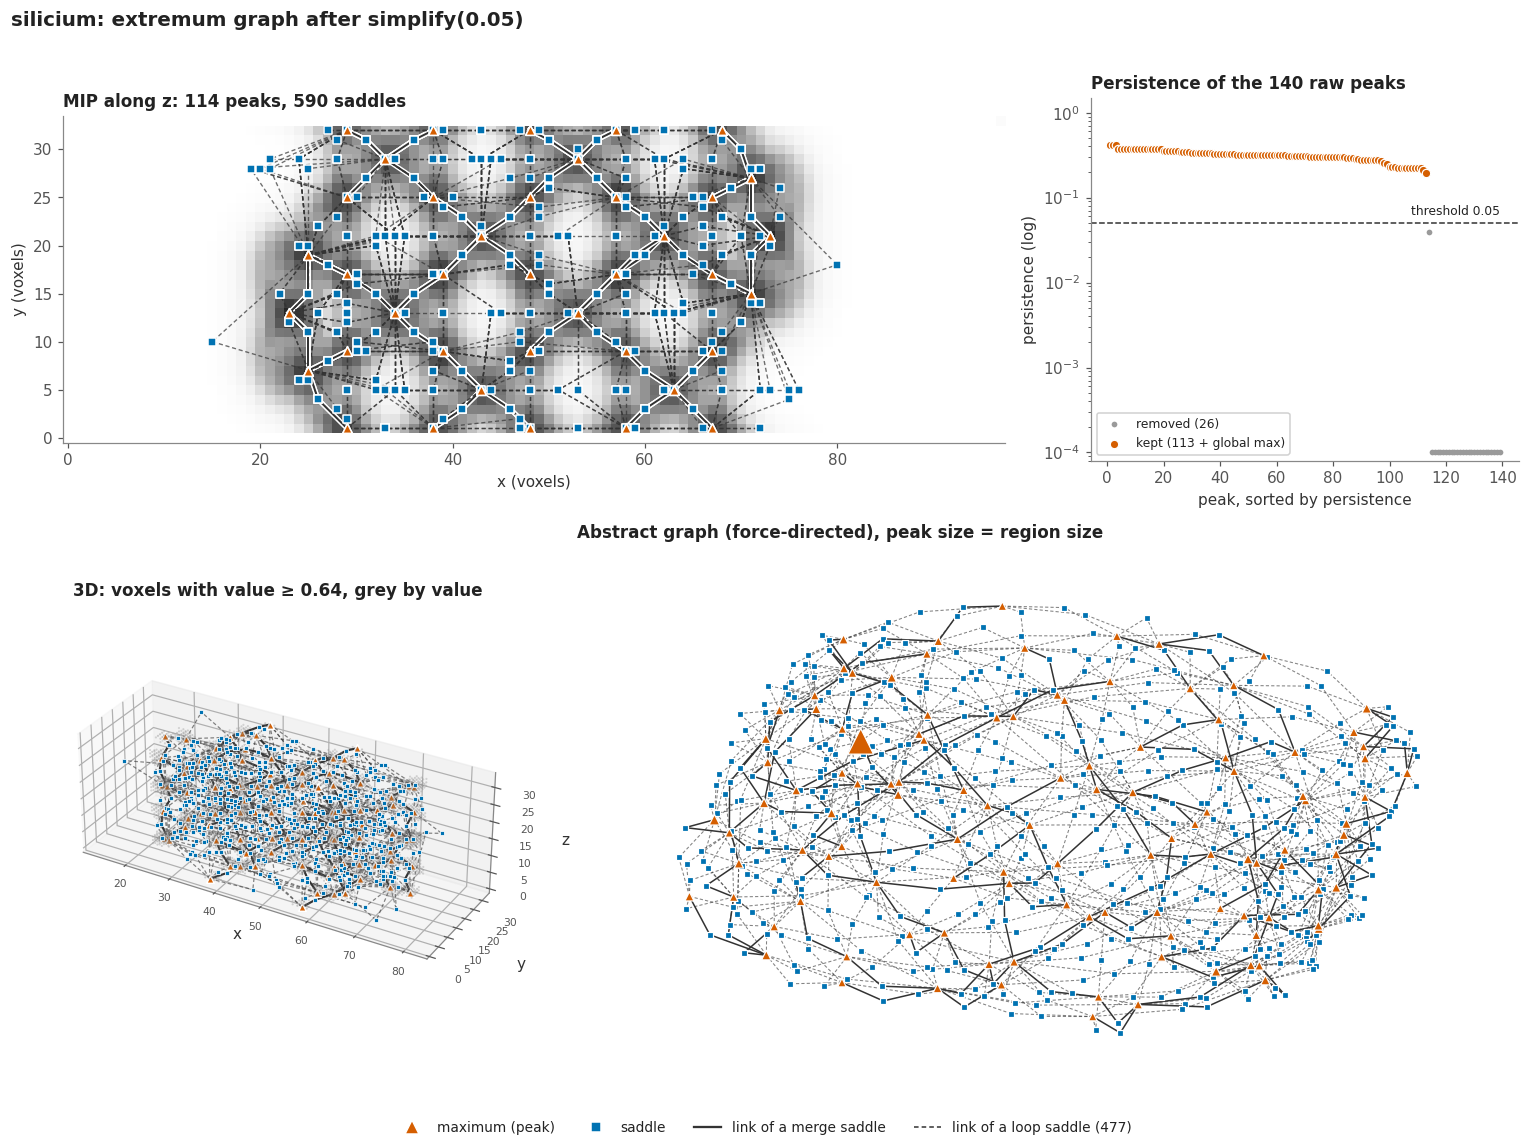

peak  position (x, y, z)   value  persistence  voxels in region
   0  ( 73,  21,   1)      1.000  inf (global)      34,746
   1  ( 23,  13,   1)      1.000         0.416         825
   2  ( 73,  21,  17)      0.996         0.412       1,283
   3  ( 23,  13,  17)      0.996         0.412       1,283
   4  ( 71,  27,  29)      0.961         0.376       1,152
   5  ( 25,  19,  29)      0.961         0.376       1,409
   6  ( 71,  15,  29)      0.961         0.376       2,557
   7  ( 25,   7,  29)      0.961         0.376       1,498
   8  ( 71,  27,  21)      0.961         0.298       1,111
   9  ( 25,  19,  21)      0.961         0.302       1,233
  10  ( 71,  15,  21)      0.961         0.302       1,326
  11  ( 25,   7,  21)      0.961         0.298       1,147
  ... 102 more


In [7]:
vol, eg_raw = compute("silicium")
eg = show(vol, eg_raw, threshold=0.05)
peak_table(vol, eg)
RESULTS["silicium"] = (vol, eg_raw, eg, 0.05)

**What it looks like.** 114 peaks on a regular lattice (the pattern repeats
every 48 voxels in x), and the saddles form a lattice too: about four out of
five saddles close a loop. The persistence plot is almost flat (all peaks
are about equally strong) and then drops sharply, so the threshold is easy
to pick. The global maximum's region (35,000 voxels) is mostly empty space,
for the same index tie-breaking reason as in `nucleon`. The abstract layout
is a hairball; this is the case the spine's level of detail and crossing
reduction are meant for.

There are about five saddles per peak. I did not check whether each link
joins two bonded atoms; some may be passes between atoms that are not
bonded.

## 6. `marschner_lobb`

A synthetic test signal: concentric rings modulated by a cosine, sampled
just below the Nyquist frequency. It is used to test reconstruction filters,
and its exact topology is mostly a sampling artefact.

Volume('marschner_lobb', 41x41x41 uint8, raw range 0..255)
  raw:  ExtremumGraph(579 peaks, 1671 saddles (1093 close a loop), N=68921)   (0.2 s)
  simplified at 0.1: ExtremumGraph(103 peaks, 303 saddles (201 close a loop), N=68921)


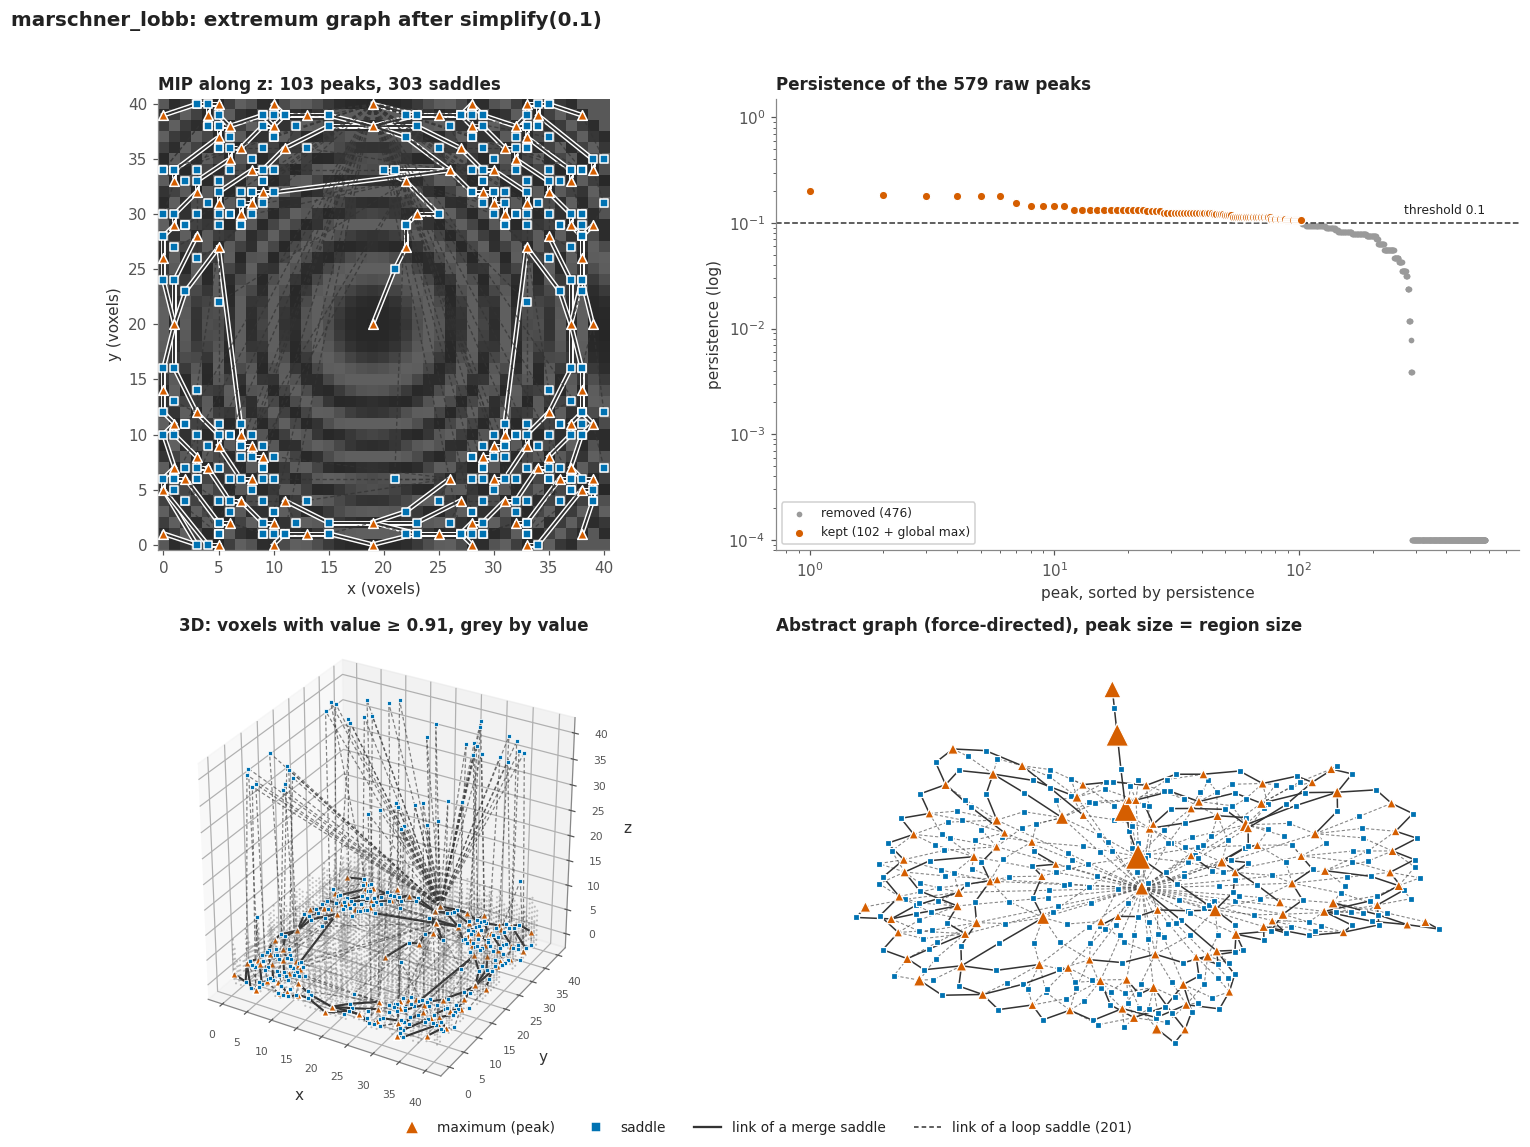

peak  position (x, y, z)   value  persistence  voxels in region
   0  ( 19,  40,   0)      1.000  inf (global)       2,034
   1  ( 31,  36,   0)      1.000         0.125         280
   2  (  7,  36,   0)      1.000         0.125         280
   3  ( 35,  32,   0)      1.000         0.125         280
   4  (  3,  32,   0)      1.000         0.125         280
   5  ( 39,  20,   0)      1.000         0.125       1,120
   6  ( 19,  20,   0)      1.000         0.200       3,560
   7  ( 35,   8,   0)      1.000         0.125         280
   8  (  3,   8,   0)      1.000         0.125         280
   9  ( 31,   4,   0)      1.000         0.125         280
  10  (  7,   4,   0)      1.000         0.125         280
  11  ( 19,   0,   0)      1.000         0.125         640
  ... 91 more


In [8]:
vol, eg_raw = compute("marschner_lobb")
eg = show(vol, eg_raw, threshold=0.1)
peak_table(vol, eg)
RESULTS["marschner_lobb"] = (vol, eg_raw, eg, 0.1)

**What it looks like.** Over a hundred peaks with persistence between 0.1 and
0.2, many with exactly the same value (0.125) because of the signal's
rotational symmetry, and a dense web of loop saddles. 40 of the 103 peaks
lie on the boundary of the grid, mostly on the bottom face z = 0, where the
signal is cut off. There is no gap in the persistence plot, so 0.1 is an
arbitrary cut. This is the worst case for a topological spine: no small set
of peaks summarises the field.

## Summary

Raw counts are before `simplify`. "Loop saddles" close a cycle in the graph;
a tree has none.

In [9]:
print(f"{'dataset':15s} {'grid':>12s} {'voxels':>10s} {'raw peaks':>10s} {'threshold':>9s} "
      f"{'peaks':>6s} {'saddles':>8s} {'loop saddles':>13s}")
for name, (vol, eg_raw, eg, th) in RESULTS.items():
    nz, ny, nx_ = vol.shape
    print(f"{name:15s} {f'{nx_}x{ny}x{nz}':>12s} {vol.num_voxels:>10,} {eg_raw.num_peaks:>10,} {th:>9} "
          f"{eg.num_peaks:>6} {eg.num_saddles:>8} {int((~eg.saddle_is_merge).sum()):>13}")

dataset                 grid     voxels  raw peaks threshold  peaks  saddles  loop saddles
nucleon             41x41x41     68,921        301     0.005      6        9             4
hydrogen_atom    128x128x128  2,097,152      6,184      0.02      5        4             0
fuel                64x64x64    262,144         88       0.1      6        6             1
neghip              64x64x64    262,144        900       0.2     22       28             7
silicium            98x34x34    113,288        140      0.05    114      590           477
marschner_lobb      41x41x41     68,921        579       0.1    103      303           201


## Observations

- **8-bit data creates plateaus.** Flat regions turn into thousands of
  zero-persistence peaks, which `simplify` with any positive threshold
  removes. Clipped maxima (value 255) give several peaks with exactly the
  same value, whose order is arbitrary. The large zero background is a
  single plateau whose region goes to whichever peak wins the index
  tie-break, so region sizes of the global maximum (or of a stray corner
  voxel, in `nucleon` and `hydrogen_atom`) include empty space.
- **The threshold depends on the dataset.** `hydrogen_atom` and `silicium`
  have a clear gap in persistence; `fuel` and `marschner_lobb` do not. The
  front end's persistence slider needs to show this plot.
- **Most real graphs are not trees.** `silicium` and `marschner_lobb` have
  several loop saddles per peak, and the force-directed layout of those
  graphs is unreadable. These are good test cases for crossing reduction and
  level of detail.
- **The loop filter (`min_loop_relief`) barely changes these graphs** (cell
  below). It was written for false passes in sparse kNN graphs, which a full
  grid does not have.

In [10]:
print("saddles kept after simplify, for three values of min_loop_relief")
print(f"{'dataset':15s} {'0.5 (default)':>14s} {'0.8':>6s} {'0.95':>6s}")
for name, (vol, eg_raw, eg, th) in RESULTS.items():
    g = grid_graph(vol.shape)
    n = [extremum_graph(vol.values.reshape(-1), g, min_loop_relief=r).simplify(th).num_saddles for r in (0.8, 0.95)]
    print(f"{name:15s} {eg.num_saddles:>14} {n[0]:>6} {n[1]:>6}")

saddles kept after simplify, for three values of min_loop_relief
dataset          0.5 (default)    0.8   0.95


nucleon                      9      9      9


hydrogen_atom                4      4      4


fuel                         6      6      6


neghip                      28     28     28


silicium                   590    590    590


marschner_lobb             303    280    268
